# Causal FX model: training, gating and calibration

This notebook shows the selected model code and the recorded full-data cloud run. Training fits three asset-specific ridge models on labels matured by December 2024. A fixed volatility gate routes their predictions; all eligible 2025 decisions calibrate intervals. The default cells read aggregate receipts and define algorithms. They do not load weights, fit models or read the 2026 evaluation panel.

In [1]:
from pathlib import Path
import os, json, hashlib, math, sys
from datetime import date
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks": ROOT = ROOT.parent
assert (ROOT / "pyproject.toml").exists()
os.chdir(ROOT)
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf8"))
def sha(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()
record = read_json("docs/gated-training-calibration.json")
policy = read_json("docs/gated-forecast-policy.json")
assert sha("docs/gated-forecast-policy.json") == record["policy_sha256"]
assert all(sha(path) == digest for path, digest in policy["production_source_sha256"].items())
print("Frozen policy:", record["policy_sha256"])
print("Default execution: aggregate receipts and algorithm definitions only")


Frozen policy: 0f511814a9cd0e4f97626bdd8deafbe3d290b25b7829e210eeed6495c4339bd0
Default execution: aggregate receipts and algorithm definitions only


## Decision-time features

The 22 predictors use current and past rates. Peer features lag one publication. The target is the log return between the next two published observations; target and execution dates never enter the feature matrix. These definitions match the source bound by the selected policy.

In [2]:
"""Causal features; delayed label t+1 -> t+2; peer features lag one observation."""
import numpy as np
import pandas as pd
from src.data.multi_asset import ASSETS, validate_panel

OWN_FEATURES = ["return_1", "momentum_3", "momentum_5", "momentum_10", "momentum_20", "momentum_60",
                "volatility_5", "volatility_20", "volatility_60", "ewma_volatility", "volatility_ratio",
                "downside_20", "drawdown_60", "zscore_20", "rsi_14", "autocorrelation_20", "skew_20", "gap_days"]
PEER_FEATURES = ["peer_return_lag1", "peer_momentum_lag1", "peer_volatility_lag1", "relative_momentum"]
FEATURES = OWN_FEATURES + PEER_FEATURES


def build_panel_features(panel, assets=ASSETS):
    panel = validate_panel(panel, assets)
    log = np.log(panel[list(assets)])
    returns = log.diff()
    result = {}
    for asset in assets:
        r, close = returns[asset], panel[asset]
        frame = pd.DataFrame({"date": panel.date, "close": close, "return_1": r})
        for period in [3, 5, 10, 20, 60]:
            frame[f"momentum_{period}"] = log[asset].diff(period)
        for period in [5, 20, 60]:
            frame[f"volatility_{period}"] = r.rolling(period).std()
        frame["ewma_volatility"] = r.ewm(span=20, adjust=False, min_periods=20).std()
        frame["volatility_ratio"] = frame.volatility_5 / frame.volatility_20.clip(lower=1e-8)
        frame["downside_20"] = np.sqrt(r.clip(upper=0).pow(2).rolling(20).mean())
        frame["drawdown_60"] = close / close.rolling(60).max() - 1
        frame["zscore_20"] = (log[asset] - log[asset].rolling(20).mean()) / log[asset].rolling(20).std().clip(lower=1e-8)
        up, down = r.clip(lower=0).rolling(14).mean(), -r.clip(upper=0).rolling(14).mean()
        frame["rsi_14"] = up / (up + down).clip(lower=1e-8)
        frame["autocorrelation_20"] = r.rolling(20).corr(r.shift(1)).fillna(0)
        frame["skew_20"] = r.rolling(20).skew().fillna(0)
        frame["gap_days"] = panel.date.diff().dt.total_seconds() / 86400
        peers = [other for other in assets if other != asset]
        frame["peer_return_lag1"] = returns[peers].mean(axis=1).shift(1)
        frame["peer_momentum_lag1"] = log[peers].diff(5).mean(axis=1).shift(1)
        frame["peer_volatility_lag1"] = returns[peers].rolling(20).std().mean(axis=1).shift(1)
        frame["relative_momentum"] = frame.momentum_20 - log[peers].diff(20).mean(axis=1).shift(1)
        frame["execution_date"] = panel.date.shift(-1)
        frame["target_date"] = panel.date.shift(-2)
        frame["target"] = r.shift(-2)
        result[asset] = frame.dropna(subset=FEATURES).reset_index(drop=True)
    return result


## Train-only ridge fit and fixed gate

Each asset has its own StandardScaler and ridge coefficients, with alpha 10,000 and no fitted intercept. Prediction is twice the ridge output when short/long volatility exceeds 1.2, and zero otherwise. Zero-routed decisions stay in metric denominators. The following functions are the readable production implementations; defining them does not fit an estimator.

In [3]:
from src.models.regime_interactions import BASE_FEATURES, SIGNALS, ALPHAS, number
def columns(interactions):
    if type(interactions) is not bool:
        raise ValueError("Explicit interaction flag required")
    return BASE_FEATURES + (
        ["bounded_volatility_gate"] + [s + "_x_gate" for s in SIGNALS]
        if interactions
        else []
    )

def design(records, interactions):
    """Only decision-time features enter this transform; no target is accessed."""
    columns(interactions)
    values = []
    for record in records:
        row = [number(record[name]) for name in BASE_FEATURES]
        if interactions:
            ratio = number(record["volatility_ratio"])
            if ratio < 0:
                raise ValueError("Negative volatility ratio")
            # Clipping before log includes the limiting case of zero short volatility.
            gate = math.log(min(2.0, max(0.5, ratio)))
            row += [gate] + [number(record[name]) * gate for name in SIGNALS]
        if not all(math.isfinite(value) for value in row):
            raise ValueError("Nonfinite interaction product")
        values.append(row)
    return values

def fit(records, alpha, interactions):
    """Heavy dependencies are imported only in the cloud fitting path."""
    if type(alpha) not in (int, float) or alpha not in ALPHAS or not records:
        raise ValueError("Declared ridge alpha and nonempty matured rows required")
    from sklearn.linear_model import Ridge
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler

    targets = [number(record["target"]) for record in records]
    return make_pipeline(StandardScaler(), Ridge(alpha=alpha, fit_intercept=False)).fit(
        design(records, interactions), targets
    )

def predict(model, records, interactions):
    return [
        number(float(value)) for value in model.predict(design(records, interactions))
    ]

def gate_predictions(predictions, ratios, threshold, multiplier):
    """No targets or future information enter this prediction transform."""
    if (
        type(threshold) not in (int, float)
        or threshold not in (1.0, 1.2)
        or type(multiplier) is not int
        or multiplier not in (1, 2)
    ):
        raise ValueError("Declared fixed threshold and multiplier required")
    if len(predictions) != len(ratios):
        raise ValueError("Aligned predictions and causal ratios required")
    values = []
    for prediction, ratio in zip(predictions, ratios):
        prediction, ratio = number(prediction), number(ratio)
        if ratio < 0:
            raise ValueError("Nonnegative volatility ratio required")
        values.append(number(multiplier * prediction) if ratio > threshold else 0.0)
    return values

def predict_records(model, records):
    """The retained estimator receives only fixed features, then causal routing."""
    raw = predict(model, records, False)
    return gate_predictions(
        raw, [number(r["volatility_ratio"]) for r in records], THRESHOLD, MULTIPLIER
    )


## Complete matured training cohort

The mean model receives only the pinned pre-2025 snapshot. Feature warm-up and the final two unmatured decisions leave 1,933 rows per asset. Source-derived decision, execution and maturity identities are checked before fitting. Model serialization must preserve predictions before a mean-freeze receipt is written.

In [4]:
from src.models.gated_forecaster import (
    MEAN_END, VERSION, DERIVED_SHA256, ASSETS,
    check_policy, validate_bundle, save_bundle, frame_records,
)
def matured_training_rows(records):
    """Every training label must already have matured inside the mean period."""
    result = []
    last = None
    for row in records:
        decision = date.fromisoformat(row["date"])
        if last is not None and decision <= last:
            raise ValueError("Unique chronological training decisions required")
        last = decision
        if row["date"] > MEAN_END:
            raise ValueError("Post-2024 mean training observation forbidden")
        if row["target_date"] is None:
            continue
        execution = date.fromisoformat(row["execution_date"])
        maturity = date.fromisoformat(row["target_date"])
        if not decision < execution < maturity:
            raise ValueError("Delayed label chronology required")
        if row["target_date"] > MEAN_END:
            raise ValueError("Future target cannot enter final mean training")
        number(row["target"])
        for name in BASE_FEATURES:
            number(row[name])
        result.append(row)
    if not result:
        raise ValueError("Matured training support required")
    return result

def validate_training_cohort(rows, observations, asset):
    """Audit feature warmup and every execution/maturity/target against source."""
    expected = observations[60:-2]
    if [r["date"] for r in rows] != [r["d"] for r in expected]:
        raise ValueError("Exact all-source matured feature coverage required")
    for i, row in enumerate(rows, start=60):
        if (
            row["execution_date"] != observations[i + 1]["d"]
            or row["target_date"] != observations[i + 2]["d"]
        ):
            raise ValueError("Final training execution or maturity identity changed")
        target = math.log(float(observations[i + 2][asset]["v"])) - math.log(
            float(observations[i + 1][asset]["v"])
        )
        if abs(number(row["target"]) - target) > 1e-14:
            raise ValueError("Final training source-derived target changed")
    return rows

def train(snapshot, policy_path, output):
    if Path(output).exists():
        raise ValueError("Preserve immutable model output")
    policy = check_policy(policy_path)
    if sha(snapshot) != DERIVED_SHA256:
        raise ValueError("Only frozen pre-2025 training source permitted")
    source = Path(snapshot).read_bytes()
    observations = json.loads(source)["observations"]
    if (
        len(observations) != 1995
        or observations[-1]["d"] != MEAN_END
        or any(r["d"] > MEAN_END for r in observations)
    ):
        raise ValueError("Complete frozen mean source required")
    from src.data.multi_asset import parse_panel
    from src.features.multi_asset import build_panel_features
    from threadpoolctl import threadpool_limits
    import joblib
    import tempfile

    panel = parse_panel(source)
    frames = build_panel_features(panel)
    rows = {a: matured_training_rows(frame_records(frames[a])) for a in ASSETS}
    for asset in ASSETS:
        validate_training_cohort(rows[asset], observations, asset)
    if any(len(v) != 1933 for v in rows.values()):
        raise ValueError("Exact final matured training cohort required")
    with threadpool_limits(limits=2):
        models = {a: fit(rows[a], 10000, False) for a in ASSETS}
    bundle = {
        "version": VERSION,
        "assets": ASSETS,
        "features": BASE_FEATURES,
        "mean_source_sha256": DERIVED_SHA256,
        "threshold": 1.2,
        "multiplier": 2,
        "models": models,
        "quantiles": None,
        "context": panel,
        "policy_sha256": sha(policy_path),
        "source_sha256": policy["production_source_sha256"],
    }
    # Prove actual final checkpoint serialization before creating the release output.
    with tempfile.TemporaryDirectory() as tmp:
        path = Path(tmp) / "model.joblib"
        joblib.dump(bundle, path)
        loaded = validate_bundle(joblib.load(path))
        delta = max(
            abs(x - y)
            for a in ASSETS
            for x, y in zip(
                predict_records(models[a], rows[a]),
                predict_records(loaded["models"][a], rows[a]),
            )
        )
        if delta > 1e-14:
            raise ValueError("Final model checkpoint replay changed")
    receipt = {
        "stage": "mean_frozen",
        "policy_sha256": sha(policy_path),
        "mean_source_sha256": DERIVED_SHA256,
        "training": {
            a: {
                "rows": len(rows[a]),
                "first_decision": rows[a][0]["date"],
                "last_decision": rows[a][-1]["date"],
                "last_target_maturity": max(r["target_date"] for r in rows[a]),
            }
            for a in ASSETS
        },
        "final_model_replay_max_abs_difference": delta,
        "calibration_accessed": False,
        "test_accessed": False,
    }
    return save_bundle(bundle, output, receipt)[1]


## Fixed 2025 interval calibration

Mean weights are frozen before the complete 2025 parent is parsed. Every decision whose execution and target mature in 2025 enters calibration: 247 per asset, 741 total. Absolute errors are divided by max(EWMA volatility, 1e-5); the 90% order statistic is used without interpolation or interval search. Under temporal dependence, nominal coverage is descriptive. The saved coefficient/scaler fingerprints must remain unchanged.

In [5]:
from src.models.gated_forecaster import (
    load_bundle, check_calibration_release, model_state_fingerprints,
)

def canonical_mean_bytes(observations):
    """Stable past-only representation; retain list order and exact source values."""
    days = [row["d"] for row in observations]
    if not days or days != sorted(set(days)) or days[-1] > MEAN_END:
        raise ValueError("Unique chronological pre2025 mean publications required")
    return (
        json.dumps(
            {"observations": observations},
            sort_keys=True,
            separators=(",", ":"),
            ensure_ascii=True,
            allow_nan=False,
        )
        + "\n"
    ).encode("utf8")

def quantile90(values):
    """Fixed finite-sample order statistic; no interpolation or width selection."""
    if not values:
        raise ValueError("Nonempty interval calibration support required")
    values = sorted(number(value) for value in values)
    if values[0] < 0:
        raise ValueError("Nonnegative calibration residuals required")
    rank = math.ceil((len(values) + 1) * 0.9)
    if rank > len(values):
        raise ValueError("Insufficient interval calibration support")
    return values[rank - 1]

def calibration_source_cohort(observations):
    """Complete eligible IDs from source chronology, independently of features."""
    days = [r["d"] for r in observations]
    if days != sorted(set(days)) or not days or days[-1] > "2025-12-31":
        raise ValueError("Unique pre-2026 calibration publications required")
    ids = [
        (asset, days[i], days[i + 1], days[i + 2])
        for asset in ASSETS
        for i in range(len(days) - 2)
        if days[i].startswith("2025-")
        and days[i + 1].startswith("2025-")
        and days[i + 2].startswith("2025-")
    ]
    digest = hashlib.sha256(json.dumps(ids, separators=(",", ":")).encode()).hexdigest()
    return ids, digest, {asset: sum(row[0] == asset for row in ids) for asset in ASSETS}

def forecast(bundle, supplied):
    """Current observations only; supplied future labels are never read."""
    validate_bundle(bundle)
    import pandas as pd
    import numpy as np
    from src.data.multi_asset import validate_panel
    from src.features.multi_asset import build_panel_features

    supplied = validate_panel(supplied)
    context = validate_panel(bundle["context"])
    overlap = supplied.merge(context, on="date", suffixes=("_new", "_old"))
    if any(
        not np.allclose(overlap[a + "_new"], overlap[a + "_old"], atol=1e-12, rtol=0)
        for a in ASSETS
    ):
        raise ValueError("Supplied observations revise frozen context")
    panel = validate_panel(
        pd.concat([context, supplied])
        .drop_duplicates("date")
        .sort_values("date")
        .reset_index(drop=True)
    )
    frames = build_panel_features(panel)
    output = []
    for asset in ASSETS:
        rows = frames[asset].loc[
            frames[asset].date.isin(supplied.date)
            & (frames[asset].date > context.date.max())
        ]
        if rows.empty:
            continue
        values = predict_records(bundle["models"][asset], frame_records(rows))
        part = pd.DataFrame({"date": rows.date, "asset": asset, "prediction": values})
        if bundle["quantiles"] is not None:
            widths = (
                np.maximum(rows.ewma_volatility.to_numpy(), 1e-5)
                * bundle["quantiles"][asset]
            )
            if not np.isfinite(widths).all():
                raise ValueError("Finite interval widths required")
            part["half_width"] = widths
            part["lower"] = part.prediction - widths
            part["upper"] = part.prediction + widths
        output.append(part)
    return (
        pd.concat(output, ignore_index=True)
        if output
        else pd.DataFrame(columns=["date", "asset", "prediction"])
    )

def calibrate(model_directory, snapshot, release_path, output):
    """Separate explicit release after mean bytes are frozen; no model fitting."""
    if Path(output).exists():
        raise ValueError("Preserve immutable calibration output")
    bundle, mean_receipt = load_bundle(model_directory)
    if mean_receipt.get("stage") != "mean_frozen" or bundle["quantiles"] is not None:
        raise ValueError("Uncalibrated frozen mean checkpoint required")
    plan = json.loads(Path(release_path).read_text(encoding="utf8"))
    provenance_path = Path(release_path).parent / "calibration-source-provenance.json"
    if plan.get("source_provenance_sha256") != sha(provenance_path):
        raise ValueError("Frozen calibration provenance bytes changed")
    provenance = json.loads(provenance_path.read_text(encoding="utf8"))
    check_calibration_release(plan, mean_receipt, snapshot, provenance)
    inherited = model_state_fingerprints(bundle["models"])
    if mean_receipt.get("mean_model_state_sha256") != inherited:
        raise ValueError("Frozen inherited mean coefficients/scaler state changed")
    content = Path(snapshot).read_bytes()
    observations = json.loads(content)["observations"]
    if any(row["d"] > "2025-12-31" for row in observations):
        raise ValueError("2026 observations cannot enter calibration")
    ids, cohort_sha, expected_counts = calibration_source_cohort(observations)
    prefix = [r for r in observations if r["d"] <= MEAN_END]
    prefix_sha = hashlib.sha256(canonical_mean_bytes(prefix)).hexdigest()
    if (
        prefix_sha != DERIVED_SHA256
        or cohort_sha != plan["expected_decision_ids_sha256"]
        or expected_counts != plan["expected_counts"]
        or len(observations) != provenance.get("source_rows")
    ):
        raise ValueError("Exact complete calibration source cohort changed")
    from src.data.multi_asset import parse_panel, validate_panel
    from src.features.multi_asset import build_panel_features
    import numpy as np
    import pandas as pd

    supplied = parse_panel(content)
    # forecast checks every overlapping saved context observation for revision.
    predicted = forecast(bundle, supplied)
    context = validate_panel(bundle["context"])
    panel = validate_panel(
        pd.concat([context, supplied])
        .drop_duplicates("date")
        .sort_values("date")
        .reset_index(drop=True)
    )
    if panel.date.max().strftime("%Y-%m-%d") != "2025-12-31":
        raise ValueError("Complete frozen 2025 publication history required")
    frames = build_panel_features(panel)
    quantiles = {}
    counts = {}
    actual_ids = []
    for asset in ASSETS:
        rows = frames[asset]
        rows = rows.loc[
            (rows.date.dt.year == 2025)
            & (rows.execution_date.dt.year == 2025)
            & (rows.target_date.dt.year == 2025)
            & rows.target.notna()
        ]
        joined = rows.merge(
            predicted.loc[predicted.asset == asset, ["date", "prediction"]],
            on="date",
            validate="one_to_one",
        )
        if len(joined) != len(rows) or not len(rows):
            raise ValueError("All matured 2025 calibration decisions required")
        actual_ids.extend(
            (asset, r["date"], r["execution_date"], r["target_date"])
            for r in frame_records(rows)
        )
        if len(rows) != expected_counts[asset]:
            raise ValueError(
                "Complete source-derived calibration decision coverage required"
            )
        residuals = (
            abs(joined.target.to_numpy() - joined.prediction.to_numpy())
            / np.maximum(joined.ewma_volatility.to_numpy(), 1e-5)
        ).tolist()
        quantiles[asset] = quantile90(residuals)
        counts[asset] = {
            "rows": len(rows),
            "first_decision": rows.date.min().strftime("%Y-%m-%d"),
            "last_decision": rows.date.max().strftime("%Y-%m-%d"),
            "last_target_maturity": rows.target_date.max().strftime("%Y-%m-%d"),
            "normalized_quantile": quantiles[asset],
        }
    if actual_ids != ids:
        raise ValueError("Exact calibration decision IDs changed")
    if model_state_fingerprints(bundle["models"]) != inherited:
        raise ValueError("Calibration changed mean coefficients or scaler state")
    calibrated = {**bundle, "quantiles": quantiles, "context": panel}
    receipt = {
        "stage": "calibrated_frozen",
        "mean_model_state_sha256": inherited,
        "calibration_decision_ids_sha256": cohort_sha,
        "source_provenance_sha256": sha(provenance_path),
        "mean_bundle_sha256": mean_receipt["bundle_sha256"],
        "policy_sha256": mean_receipt["policy_sha256"],
        "calibration_release_sha256": sha(release_path),
        "calibration_source_sha256": sha(snapshot),
        "calibration": counts,
        "mean_refitted": False,
        "test_accessed": False,
        "coverage_interpretation": "Descriptive under serial dependence; no exchangeability guarantee",
    }
    return save_bundle(calibrated, output, receipt)[1]


## Chronological validation

These are measured 2021–24 validation folds, with 2,961 decisions in each pooled comparison. The fixed gate has a small validation improvement; repeated validation and a descriptive uncertainty interval crossing zero limit the evidence. The table does not select a different policy during notebook execution. Detailed selection checks are in notebook 04.

year,2021,2022,2023,2024
model,,,,
gate_1.2_2,0.003500,0.004856,0.004003,0.003041
linear_10000,0.003503,0.004867,0.004001,0.003047
zero,0.003510,0.004874,0.004001,0.003042


,model,rows,validation_rmse
0,zero,2961,0.003914
1,linear_10000,2961,0.003911
2,gate_1.2_2,2961,0.003906


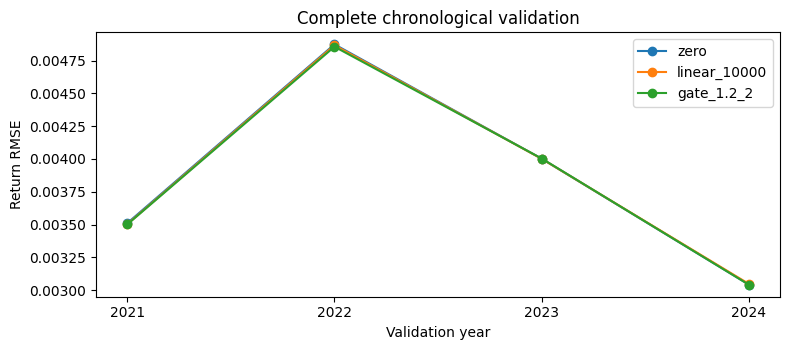

In [6]:
fold_rows = []
for model in record["validation"]:
    for fold in model["folds"]:
        fold_rows.append({"model": model["name"], **fold})
folds = pd.DataFrame(fold_rows)
display(folds.pivot(index="model", columns="year", values="rmse"))
display(pd.DataFrame([
    {"model": model["name"], "rows": model["validation"]["n"],
     "validation_rmse": model["validation"]["rmse"]}
    for model in record["validation"]
]))
fig, ax = plt.subplots(figsize=(8, 3.6))
for name, values in folds.groupby("model", sort=False):
    ax.plot(values.year, values.rmse, marker="o", label=name)
ax.set(title="Complete chronological validation", xlabel="Validation year", ylabel="Return RMSE")
ax.set_xticks(sorted(folds.year.unique()))
ax.legend()
fig.tight_layout()
plt.show()


## Actual fresh-run proof

The public workflow ran in an empty private cloud workspace with only pinned source files and training/calibration inputs. It mounted no existing model artifacts. Three fresh fits reproduced the selected numerical state and model bytes. The following outputs come from the audited cloud proof, not from a notebook training run. The 747 forecasts cover every 2025 publication; the final two decisions per asset have no matured calibration label.

In [7]:
cold = record["coldstart_integration"]
assert cold["actual_fresh_mean_fits"] == 3
assert cold["matured_training_rows"] == sum(x["rows"] for x in record["training"].values()) == 5799
assert cold["calibration_rows"] == sum(x["rows"] for x in record["calibration"].values()) == 741
assert cold["pre2026_mean_forecast_rows"] == 747
assert cold["reference_numerical_state_equal"] is True
assert cold["mean_final_reload_max_delta"] == 0
assert cold["original_model_artifacts_mounted"] is False
assert cold["accuracy_evaluated"] is False and cold["test_accessed"] is False
display(pd.DataFrame([
    {"asset": asset, "mean_training_rows": record["training"][asset]["rows"],
     "last_training_maturity": record["training"][asset]["last_target_maturity"],
     "calibration_rows": record["calibration"][asset]["rows"],
     "normalized_90pct_quantile": record["calibration"][asset]["normalized_quantile"]}
    for asset in policy["assets"]
]))
display(pd.DataFrame([{
    "fresh_fits": cold["actual_fresh_mean_fits"], "training_rows": cold["matured_training_rows"],
    "forecast_rows_2025": cold["pre2026_mean_forecast_rows"], "calibration_rows": cold["calibration_rows"],
    "mean_reload_max_delta": cold["mean_final_reload_max_delta"],
    "reference_state_equal": cold["reference_numerical_state_equal"]
}]))
print("Audited cold-start proof SHA256:", cold["proof_sha256"])
print("Actual numerical runtime:", cold["environment"])


,asset,mean_training_rows,last_training_maturity,calibration_rows,normalized_90pct_quantile
0,FXEURCAD,1933,2024-12-31,247,1.617421
1,FXGBPCAD,1933,2024-12-31,247,1.804818
2,FXAUDCAD,1933,2024-12-31,247,1.581997


,fresh_fits,training_rows,forecast_rows_2025,calibration_rows,mean_reload_max_delta,reference_state_equal
0,3,5799,747,741,0.0,True


Audited cold-start proof SHA256: 28ef518d9166b28edb8533941985c10cfef596faf77045218f01883f4cdf4dc4
Actual numerical runtime: {'python': '3.13.15', 'numpy': '2.2.6', 'pandas': '2.2.3', 'scipy': '1.15.3', 'scikit-learn': '1.6.1', 'joblib': '1.4.2', 'threadpoolctl': '3.6.0'}


## Run the same public workflow

Optional execution is disabled. Supply the pinned pre-2025 snapshot separately; training must not inspect the 2025 parent first. Use the recorded numerical runtime and fresh output directories. Train creates an authenticated own mean freeze; calibration binds that actual new receipt and bundle. The forecast command uses the fresh mean checkpoint on pre-2026 observations. After calibration, saved context ends on 2025-12-31, so this historical source cannot produce a new post-calibration forecast. No command here evaluates 2026 targets.

In [8]:
RUN_FRESH = False
PRE2025_SNAPSHOT = Path("data/processed/development-through2024.json")
DEVELOPMENT_PARENT = Path("data/external/gated-development/source.json")
RUN_DIRECTORY = Path("models/my-fresh-gated-run")
CALIBRATION_DIRECTORY = Path("models/my-fresh-gated-calibration")
FORECAST_OUTPUT = Path("data/reports/my-fresh-2025-forecasts.csv")
if RUN_FRESH:
    import importlib.metadata, platform, subprocess
    expected = cold["environment"]
    assert platform.python_version() == expected["python"]
    assert all(importlib.metadata.version(name) == version for name, version in expected.items() if name != "python")
    subprocess.run([sys.executable, "-m", "src.data.gated_fetch", "mean",
                    "--output", str(PRE2025_SNAPSHOT)], check=True)
    subprocess.run([sys.executable, "-m", "src.gated_workflow", "train",
                    "--snapshot", str(PRE2025_SNAPSHOT), "--policy", "docs/gated-forecast-policy.json",
                    "--output", str(RUN_DIRECTORY)], check=True)
    own_freeze_sha = sha(RUN_DIRECTORY / "mean-freeze.json")
    subprocess.run([sys.executable, "-m", "src.data.gated_fetch", "calibration",
                    "--run", str(RUN_DIRECTORY), "--policy", "docs/gated-forecast-policy.json",
                    "--freeze-sha256", own_freeze_sha, "--output", str(DEVELOPMENT_PARENT)], check=True)
    mean_receipt_sha = sha(RUN_DIRECTORY / "mean" / "receipt.json")
    subprocess.run([sys.executable, "-m", "src.gated_workflow", "forecast",
                    "--model", str(RUN_DIRECTORY / "mean"), "--snapshot", str(DEVELOPMENT_PARENT),
                    "--policy", "docs/gated-forecast-policy.json", "--policy-sha256", record["policy_sha256"],
                    "--receipt-sha256", mean_receipt_sha, "--output", str(FORECAST_OUTPUT)], check=True)
    subprocess.run([sys.executable, "-m", "src.gated_workflow", "calibrate",
                    "--run", str(RUN_DIRECTORY), "--parent", str(DEVELOPMENT_PARENT),
                    "--policy", "docs/gated-forecast-policy.json", "--freeze-sha256", own_freeze_sha,
                    "--output", str(CALIBRATION_DIRECTORY)], check=True)
print("Optional fresh training/calibration executed:", RUN_FRESH)


Optional fresh training/calibration executed: False


## Reading the outputs

Validation supports a narrowly improved fixed gate, not a trading-profit claim. Fresh-run numerical agreement checks reproducibility, not independent accuracy. Notebook 03 covers the already-observed retrospective evaluation; notebook 04 contains the detailed validation and training/calibration audit. Bank of Canada reference rates are not executable quotes, and current API snapshots are not historical as-published vintages.